# PFAS comparison 2 — Transformer experiments
Google Colab / Jupyter notebook | grouped 5-fold CV + model comparison + SHAP + attention


## 1. Install and import

In [1]:
%pip -q install tensorflow==2.21.0 numpy==2.3.5 pandas==2.2.3 scikit-learn==1.8.0 shap==0.53.0 openpyxl matplotlib joblib

In [2]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
os.environ.setdefault('OMP_NUM_THREADS','2')
import json,time,gc,random,hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import GlobalMaxPooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error,mean_absolute_error

try:
 tf.config.threading.set_intra_op_parallelism_threads(2)
 tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
 pass

import matplotlib.pyplot as plt
import shap,joblib
from IPython.display import display
out=Path('transformer_comparison_results');out.mkdir(exist_ok=True)

import shutil, platform
from importlib.metadata import version
from sklearn.metrics import r2_score
REUSE_COMPLETED = True
BOOTSTRAPS = 2000
SHAP_ROWS = 8
SHAP_BACKGROUND = 12
SHAP_CYCLES = 3

def metrics(y,p):
 return {'RMSE (pp)':float(np.sqrt(mean_squared_error(y,p))),
         'MAE (pp)':float(mean_absolute_error(y,p)),
         'R2':float(r2_score(y,p)), 'Bias (pp)':float(np.mean(p-y))}

def save_plot(fig,name):
 fig.tight_layout()
 for ext in ['png','pdf']:fig.savefig(out/f'{name}.{ext}',dpi=220,bbox_inches='tight')
 display(fig);plt.close(fig)


## 2. Load Excel dataset

In [3]:
DATA_FILE=Path('AFFF_data_final_20240308(1).xlsx')
if not DATA_FILE.exists():
 try:
  from google.colab import files
 except ImportError:
  raise FileNotFoundError('Place the Excel dataset beside this notebook or set DATA_FILE to its path.')
 uploaded=files.upload();DATA_FILE=Path(next(name for name in uploaded if name.endswith('.xlsx')))


Saving AFFF_data_final_20240308.xlsx to AFFF_data_final_20240308.xlsx


## 3. Preprocess the experimental variables

In [4]:
df=pd.read_excel(DATA_FILE,sheet_name='data').rename(columns={'MWCO (Da)':'MWCO','Isoelectric point':'IEP','Water contact angle':'CA','Compound size (Å)':'Size','Initial concentration (ng/L)':'Init_conc','IS (mM)':'IS','Pressure (psi)':'Pres'})
df['SMILES']=df.SMILES.str.replace('[()=]','',regex=True)
df['charge']=-1/(1+10**np.clip(df.pKa-df.pH,-100,100))
df['charge_product']=(df.IEP-df.pH)*df.charge
df['Init_conc']=df.Init_conc/df.Mw
df['group']=df.ref_ID.map(str)+df.PFAS
input_vars=['MWCO','CA','Size','log Kow','Init_conc','Pres','IS','charge_product']
train=df[df.ref_ID.astype(str)!='1'].reset_index(drop=True);test=df[df.ref_ID.astype(str)=='1'].reset_index(drop=True)
y_train=train.Removal_rate.to_numpy(np.float32)

print(f'Training: {len(train)}; experimental test: {len(test)}')
assert len(train)==457 and len(test)==77, 'Unexpected split: check ref_ID and workbook.'
assert not df[input_vars+['Removal_rate','SMILES']].isna().any().any()
assert np.isfinite(df[input_vars+['Removal_rate']].to_numpy(dtype=float)).all()
assert df.Removal_rate.between(0,100).all()
assert set(train.group).isdisjoint(set(test.group))


Training: 457; experimental test: 77


## 4. Select features and define the Transformer

In [5]:
FF_LAYERS=0
def positional_encoding(length, depth):

  positions = np.arange(length)[:, np.newaxis]
  depths = np.arange(depth)[np.newaxis, :]/depth

  angle_rates = 1 / (10000**depths)
  angle_rads = positions * angle_rates

  pos_encoding = np.concatenate(
      [np.sin(angle_rads), np.cos(angle_rads)],
      axis=-1)

  pos_encoding = pos_encoding[:, :depth]

  return tf.cast(pos_encoding, dtype=tf.float32)

class PositionalEmbedding(tf.keras.layers.Layer):
  def __init__(self, d_model):
    super().__init__()
    self.d_model = d_model
    self.dense = tf.keras.layers.Dense(d_model)
    self.pos_encoding = positional_encoding(length=d_model, depth=d_model)

  def call(self, x):
    length = tf.shape(x)[1]
    x = tf.expand_dims(x, -1)
    x = self.dense(x)
    x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))
    x = x + self.pos_encoding[:length, :]
    return x

class BaseAttention(tf.keras.layers.Layer):
  def __init__(self, **kwargs):
    super().__init__()
    self.mha = tf.keras.layers.MultiHeadAttention(**kwargs)
    self.layernorm = tf.keras.layers.LayerNormalization()
    self.add = tf.keras.layers.Add()

class GlobalSelfAttention(BaseAttention):
    def call(self, x):
        attn_output = self.mha(
            query=x,
            value=x,
            key=x)
        x = self.add([x, attn_output])
        x = self.layernorm(x)
        return x

class FeedForward(tf.keras.layers.Layer):
  def __init__(self, d_model, dff, FF_num_layers, dropout_rate=0.1):
    super().__init__()
    self.seq = tf.keras.Sequential()
    for _ in range(int(FF_num_layers)):
        self.seq.add(tf.keras.layers.Dense(dff, activation='gelu'))
        self.seq.add(tf.keras.layers.Dropout(dropout_rate))
        dff = dff // 2
    self.seq.add(tf.keras.layers.Dense(d_model))
    self.linear = tf.keras.layers.Dense(d_model)
    self.add = tf.keras.layers.Add()
    self.layer_norm = tf.keras.layers.LayerNormalization()

  def call(self, x):
    seq_output = self.seq(x)
    x = self.add([x, seq_output])
    x = self.linear(x)
    x = self.layer_norm(x)
    return x

class EncoderLayer(tf.keras.layers.Layer):
  def __init__(self,*, d_model, num_heads, dff, dropout_rate=0.1):
    super().__init__()

    self.self_attention = GlobalSelfAttention(
        num_heads=num_heads,
        key_dim=d_model,
        dropout=dropout_rate)

    self.ffn = FeedForward(d_model, dff, FF_num_layers=FF_LAYERS, dropout_rate=dropout_rate)

  def call(self, x):
    x = self.self_attention(x)
    x = self.ffn(x)
    return x

class Encoder(tf.keras.layers.Layer):
  def __init__(self, *, num_layers, d_model, num_heads, dff, dropout_rate=0.1):
    super().__init__()

    self.d_model = d_model
    self.num_layers = num_layers

    self.pos_embedding = PositionalEmbedding(d_model=d_model, )

    self.enc_layers = [
        EncoderLayer(d_model=d_model,
                     num_heads=num_heads,
                     dff=dff,
                     dropout_rate=dropout_rate)
        for _ in range(num_layers)]
    self.dropout = tf.keras.layers.Dropout(dropout_rate)

  def call(self, x):
    x = self.pos_embedding(x)
    x = self.dropout(x)

    for i in range(self.num_layers):
      x = self.enc_layers[i](x)
    return x

class Transformer(tf.keras.Model):
  def __init__(self, *, num_layers, d_model, num_heads, dff,
               dropout_rate=0.1):
    super().__init__()
    self.encoder = Encoder(num_layers=num_layers, d_model=d_model,
                           num_heads=num_heads, dff=dff,
                           dropout_rate=dropout_rate)

    self.final_layer = tf.keras.layers.Dense(1, activation='linear')

  def call(self, inputs):
    x = inputs
    x = self.encoder(x)
    x = GlobalMaxPooling1D()(x)
    pred = self.final_layer(x)
    return pred

def inputs(fit,others):
 scaler=StandardScaler().fit(fit[input_vars]);tokenizer=Tokenizer(char_level=True,oov_token=None)
 tokenizer.fit_on_texts(fit.SMILES.tolist())
 def transform(frame):
  tokens=pad_sequences(tokenizer.texts_to_sequences(frame.SMILES.tolist()),maxlen=56,padding='post')
  return np.concatenate([scaler.transform(frame[input_vars]),tokens],axis=1).astype(np.float32)
 return transform(fit),[transform(frame) for frame in others],scaler,tokenizer

params=dict(num_layers=1,d_model=64,num_heads=2,dff=16,dropout_rate=.1)
checkpoints=[50,100,200,400]
seeds=[42,43,44]
def fit_model(X,y,validation,scaled,seed,max_epochs,save_path=None):
 tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(seed)
 model=Transformer(**params);model(tf.zeros((1,64)))
 optimizer=tf.keras.optimizers.Adam(learning_rate=.001)
 mean=float(y.mean()) if scaled else 0.;std=float(y.std()) if scaled else 1.
 Y=((y-mean)/std).astype(np.float32)[:,None]
 @tf.function(input_signature=[tf.TensorSpec([None,64],tf.float32),tf.TensorSpec([None,1],tf.float32)])
 def step(a,b):
  with tf.GradientTape() as tape:
   pred=model(a,training=True);loss=tf.reduce_mean(tf.square(pred-b))
  grad=tape.gradient(loss,model.trainable_variables);optimizer.apply_gradients(zip(grad,model.trainable_variables))
  return loss
 @tf.function(input_signature=[tf.TensorSpec([None,64],tf.float32)])
 def infer(a):return model(a,training=False)
 rng=np.random.default_rng(seed);preds={};history=[]
 start=time.time()
 for epoch in range(1,max_epochs+1):
  order=rng.permutation(len(y));losses=[]
  for a in range(0,len(y),64):
   idx=order[a:a+64];losses.append(float(step(X[idx],Y[idx])))
  if epoch in checkpoints or epoch==max_epochs:
   print(f'  Epoch {epoch}/{max_epochs}',flush=True)
   preds[epoch]=[infer(v).numpy().ravel()*std+mean for v in validation]
   history.append({'epoch':epoch,'loss':float(np.mean(losses))})
 if save_path:model.save_weights(save_path)
 return preds,history,model,mean,std


experiments={
 'baseline':{'name':'Transformer baseline','scaled':False,'log':False,'ff':0},
 'target_scaling':{'name':'Transformer + target scaling','scaled':True,'log':False,'ff':0},
 'log_concentration':{'name':'Transformer + log concentration','scaled':False,'log':True,'ff':0},
 'feedforward':{'name':'Transformer + feed-forward correction','scaled':False,'log':False,'ff':1}}

def prepare(frame,mode):
 frame=frame.copy()
 if experiments[mode]['log']:frame['Init_conc']=np.log10(frame.Init_conc.clip(lower=1e-8))
 return frame

folds=list(GroupKFold(5).split(train,y_train,train.group))
for a,b in folds:assert set(train.iloc[a].group).isdisjoint(set(train.iloc[b].group))
settings={'source_commit':'7965862dda73615c7f0f64422cd20b4c6548d584',
 'params':params,'checkpoints':checkpoints,'seeds':seeds,'cv_seed':42,
 'learning_rate':.001,'batch_size':64,'experiments':experiments,
 'groups':'ref_ID + PFAS; not whole-study holdout','test_previously_inspected':True,
 'preprocessing':'Training-fitted scaler/tokenizer; fold-fitted during CV',
 'data_sha256':hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
 'versions':{p:version(p) for p in ['numpy','pandas','scikit-learn','keras','shap']},
 'tensorflow':tf.__version__,'python':platform.python_version()}
# Notebook source is unavailable to inspect in some front ends; the fixed code revision
# below must be changed if the architecture or training function is edited.
settings['code_revision']='transformer-comparison-20261010-v1'
run_id=hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()[:16]
cache=out/run_id;cache.mkdir(exist_ok=True)
(cache/'settings.json').write_text(json.dumps(settings,indent=2))
print('Run:',run_id,'| GPU:',bool(tf.config.list_physical_devices('GPU')))


Run: 71b539b4d55e13a1 | GPU: True


## 5. Grouped 5-fold CV and epoch selection

In [6]:
oof={(mode,ep):np.zeros(len(train)) for mode in experiments for ep in checkpoints}
fold_rows=[]
for fold,(a,b) in enumerate(folds):
 for mode,cfg in experiments.items():
  path=cache/f'cv_{mode}_{fold}.npz'
  if REUSE_COMPLETED and path.exists():
   saved=np.load(path);assert np.array_equal(saved['indices'],b)
   pred={ep:[saved[str(ep)]] for ep in checkpoints}
   print(f'Fold {fold+1}/5: {mode} — loaded completed fit',flush=True)
  else:
   frame=prepare(train,mode);X,(V,),_,_=inputs(frame.iloc[a],[frame.iloc[b]])
   FF_LAYERS=cfg['ff'];start=time.time()
   pred,history,model,_,_=fit_model(X,y_train[a],[V],cfg['scaled'],42,max(checkpoints))
   np.savez_compressed(path,indices=b,**{str(ep):pred[ep][0] for ep in checkpoints})
   pd.DataFrame(history).to_csv(cache/f'history_{mode}_{fold}.csv',index=False)
   print(f'Fold {fold+1}/5: {mode} — {time.time()-start:.0f}s',flush=True)
  for ep in checkpoints:
   oof[(mode,ep)][b]=pred[ep][0]
   fold_rows.append({'Model':mode,'Fold':fold+1,'Epochs':ep,**metrics(y_train[b],pred[ep][0])})
scores=pd.DataFrame([{'Model':mode,'Epochs':ep,'CV RMSE':metrics(y_train,p)['RMSE (pp)'],'CV MAE':metrics(y_train,p)['MAE (pp)']} for (mode,ep),p in oof.items()]).sort_values(['CV RMSE','Model','Epochs'])
chosen=scores.drop_duplicates('Model').set_index('Model')
best_mode=scores.iloc[0].Model
locked={'selected_model':best_mode,'epochs':{mode:int(chosen.loc[mode,'Epochs']) for mode in experiments},'rule':'Minimum training grouped OOF RMSE'}
(cache/'locked_choice.json').write_text(json.dumps(locked,indent=2))
fold_scores=pd.DataFrame(fold_rows)
display(scores.round(4));print('Selected using validation only:',experiments[best_mode]['name'])


  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 1/5: baseline — 33s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 1/5: target_scaling — 21s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 1/5: log_concentration — 22s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 1/5: feedforward — 24s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 2/5: baseline — 24s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 2/5: target_scaling — 22s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 2/5: log_concentration — 21s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 2/5: feedforward — 24s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 3/5: baseline — 28s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 3/5: target_scaling — 22s
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Fold 3/5: log_c

,Model,Epochs,CV RMSE,CV MAE
7,target_scaling,400,8.2269,5.4886
4,target_scaling,50,8.7776,6.3528
6,target_scaling,200,8.8762,6.0144
15,feedforward,400,9.6391,6.5087
14,feedforward,200,9.6808,7.4134
5,target_scaling,100,9.7493,7.0924
11,log_concentration,400,10.3005,7.0509
3,baseline,400,10.3500,7.7969
13,feedforward,100,10.8598,8.9964
8,log_concentration,50,11.0127,9.8790


Selected using validation only: Transformer + target scaling


## 6. Final training and comparison with the paper

In [7]:
final={}
for mode,cfg in experiments.items():
 frame=prepare(train,mode);other=prepare(test,mode)
 X,(T,),scaler,tokenizer=inputs(frame,[other])
 ep=locked['epochs'][mode];train_preds=[];test_preds=[]
 for seed in seeds:
  path=cache/f'final_{mode}_{seed}.npz';weights=cache/f'{mode}_{seed}.weights.h5'
  if REUSE_COMPLETED and path.exists() and weights.exists():
   saved=np.load(path);tr=saved['train'];te=saved['test']
  else:
   FF_LAYERS=cfg['ff']
   pred,history,model,mean,std=fit_model(X,y_train,[X,T],cfg['scaled'],seed,ep,str(weights))
   tr,te=pred[ep];np.savez_compressed(path,train=tr,test=te)
  train_preds.append(tr);test_preds.append(te)
  print('Completed:',mode,'seed',seed,flush=True)
 final[mode]={'train':np.mean(train_preds,axis=0),'test':np.mean(test_preds,axis=0),'seed_test':np.array(test_preds)}
 joblib.dump(scaler,cache/f'{mode}_scaler.joblib')
 (cache/f'{mode}_tokenizer.json').write_text(tokenizer.to_json())
# Test labels enter scoring only after the selection above is fixed.
y_test=test.Removal_rate.to_numpy()
results=pd.DataFrame([{'Model':experiments[mode]['name'],'Selected by CV':mode==best_mode,
 'Epochs':locked['epochs'][mode],'CV RMSE (pp)':chosen.loc[mode,'CV RMSE'],
 'Train RMSE (pp)':metrics(y_train,p['train'])['RMSE (pp)'],
 'Train MAE (pp)':metrics(y_train,p['train'])['MAE (pp)'],
 **{'Test '+k:v for k,v in metrics(y_test,p['test']).items()}} for mode,p in final.items()])
test_prediction=final[best_mode]['test']
comparison=pd.DataFrame({'Model':['Multimodal Transformer (Paper)',experiments[best_mode]['name']+' (New)'],
 'Test RMSE (%)':[5.9,metrics(y_test,test_prediction)['RMSE (pp)']],
 'Test MAE (%)':[4.5,metrics(y_test,test_prediction)['MAE (pp)']]})
display(comparison.round(4));display(results.round(4))
print('Published reference is not a matched reproduction. % error columns denote percentage points.')
print('Selected model below published RMSE:',bool(comparison.iloc[1,1]<5.9))


  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: baseline seed 42
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: baseline seed 43
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: baseline seed 44
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: target_scaling seed 42
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: target_scaling seed 43
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: target_scaling seed 44
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: log_concentration seed 42
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: log_concentration seed 43
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: log_concentration seed 44
  Epoch 50/400
  Epoch 100/400
  Epoch 200/400
  Epoch 400/400
Completed: feedforward seed 42
  Epoch 50/400
  Epoch 100/400
  Epoch 200

,Model,Test RMSE (%),Test MAE (%)
0,Multimodal Transformer (Paper),5.9000,4.5000
1,Transformer + target scaling (New),9.2284,6.8781


,Model,Selected by CV,Epochs,CV RMSE (pp),Train RMSE (pp),Train MAE (pp),Test RMSE (pp),Test MAE (pp),Test R2,Test Bias (pp)
0,Transformer baseline,False,400,10.3500,4.8833,3.3870,7.3161,5.5097,0.1848,3.1405
1,Transformer + target scaling,True,400,8.2269,3.6569,2.2025,9.2284,6.8781,-0.2970,5.5102
2,Transformer + log concentration,False,400,10.3005,4.7347,3.3249,7.0968,5.1278,0.2330,3.4472
3,Transformer + feed-forward correction,False,400,9.6391,4.6940,3.1495,7.4456,5.5377,0.1557,4.5645


Published reference is not a matched reproduction. % error columns denote percentage points.
Selected model below published RMSE: False


## 7. Error analysis, seed variability and uncertainty

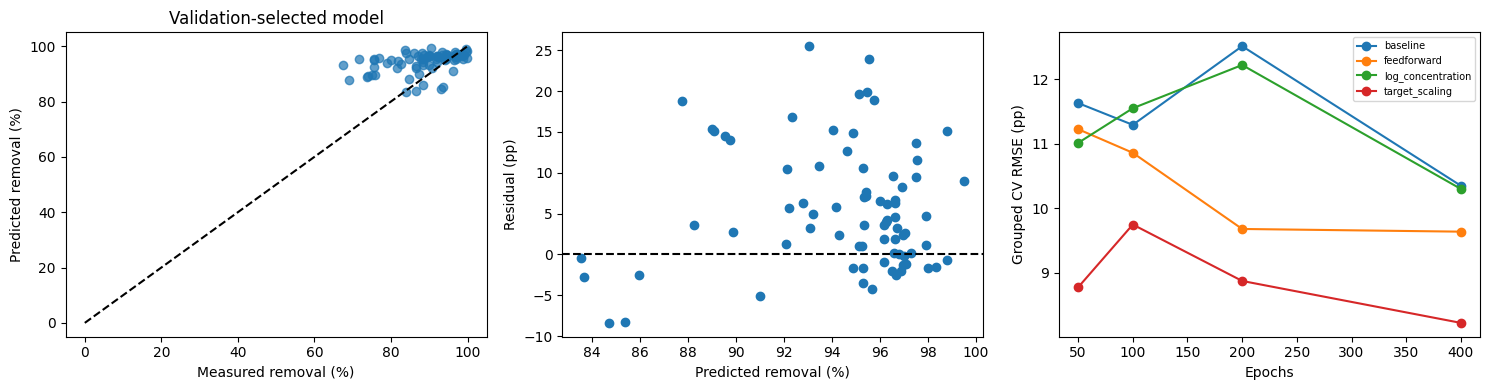

,Model,Seed,RMSE (pp),MAE (pp),R2,Bias (pp)
0,baseline,42,7.6495,6.0134,0.1088,3.5808
1,baseline,43,7.9916,6.0504,0.0273,4.0537
2,baseline,44,6.8730,5.2586,0.2806,1.7869
3,target_scaling,42,7.3091,5.8260,0.1864,1.4781
4,target_scaling,43,10.6235,8.1905,-0.7188,7.0249
5,target_scaling,44,11.2977,8.7985,-0.9439,8.0277
6,log_concentration,42,8.3841,6.4073,-0.0705,3.6313
7,log_concentration,43,7.9858,5.8318,0.0288,4.9677
8,log_concentration,44,6.2932,4.5697,0.3968,1.7426
9,feedforward,42,6.3053,4.5371,0.3945,2.2323


,Grouping,Group,n,Model,RMSE (pp),MAE (pp)
0,PFAS,FOSA,7,baseline,7.4745,6.2298
1,PFAS,FOSA,7,target_scaling,9.4760,8.2080
2,PFAS,FOSA,7,log_concentration,8.3324,7.0170
3,PFAS,FOSA,7,feedforward,9.6946,8.0066
4,PFAS,PFBA,7,baseline,7.7933,7.1911
...,...,...,...,...,...,...
59,Membrane,NF270-PEI,11,feedforward,4.3925,3.4911
60,Membrane,NF90,11,baseline,3.6090,2.9051
61,Membrane,NF90,11,target_scaling,5.0976,3.6142
62,Membrane,NF90,11,log_concentration,3.9348,2.8257


,Model,RMSE 95% low,RMSE 95% high,RMSE difference vs baseline,Difference 95% low,Difference 95% high
0,baseline,6.5363,8.0247,0.0000,0.0000,0.0000
1,target_scaling,7.3293,11.1987,1.9123,0.3711,3.6497
2,log_concentration,6.0354,8.0231,-0.2194,-0.7414,0.3340
3,feedforward,6.4397,8.2925,0.1295,-0.3928,0.7402


Negative differences favour the variant; intervals are exploratory PFAS-cluster bootstrap intervals.


In [8]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].scatter(y_test,test_prediction,alpha=.7);axes[0].plot([0,100],[0,100],'k--');axes[0].set(xlabel='Measured removal (%)',ylabel='Predicted removal (%)',title='Validation-selected model')
axes[1].scatter(test_prediction,test_prediction-y_test);axes[1].axhline(0,color='k',linestyle='--');axes[1].set(xlabel='Predicted removal (%)',ylabel='Residual (pp)')
for mode,g in scores.groupby('Model'):
 g=g.sort_values('Epochs');axes[2].plot(g.Epochs,g['CV RMSE'],marker='o',label=mode)
axes[2].set(xlabel='Epochs',ylabel='Grouped CV RMSE (pp)');axes[2].legend(fontsize=7)
save_plot(fig,'diagnostics')
seed_scores=pd.DataFrame([{'Model':mode,'Seed':seed,**metrics(y_test,p)} for mode,v in final.items() for seed,p in zip(seeds,v['seed_test'])])
display(seed_scores.round(4))
subgroup_rows=[]
for field in ['PFAS','Membrane']:
 for label,indices in test.groupby(field).groups.items():
  idx=np.array(list(indices))
  for mode,p in final.items():
   subgroup_rows.append({'Grouping':field,'Group':label,'n':len(idx),'Model':mode,
    'RMSE (pp)':np.sqrt(np.mean((p['test'][idx]-y_test[idx])**2)),
    'MAE (pp)':np.mean(np.abs(p['test'][idx]-y_test[idx]))})
subgroups=pd.DataFrame(subgroup_rows);display(subgroups.round(4))
clusters=[np.array(list(idx)) for idx in test.groupby('PFAS').groups.values()]
rng=np.random.default_rng(42)
resamples=[np.concatenate([clusters[i] for i in rng.integers(0,len(clusters),len(clusters))]) for _ in range(BOOTSTRAPS)]
intervals=[]
base=final['baseline']['test']
for mode,p in final.items():
 values=[];deltas=[]
 for idx in resamples:
  r=np.sqrt(np.mean((y_test[idx]-p['test'][idx])**2))
  values.append(r);deltas.append(r-np.sqrt(np.mean((y_test[idx]-base[idx])**2)))
 lo,hi=np.percentile(values,[2.5,97.5]);dl,dh=np.percentile(deltas,[2.5,97.5])
 intervals.append({'Model':mode,'RMSE 95% low':lo,'RMSE 95% high':hi,
  'RMSE difference vs baseline':metrics(y_test,p['test'])['RMSE (pp)']-metrics(y_test,base)['RMSE (pp)'],
  'Difference 95% low':dl,'Difference 95% high':dh})
intervals=pd.DataFrame(intervals);display(intervals.round(4))
print('Negative differences favour the variant; intervals are exploratory PFAS-cluster bootstrap intervals.')


## 8. SHAP explanation and attention analysis

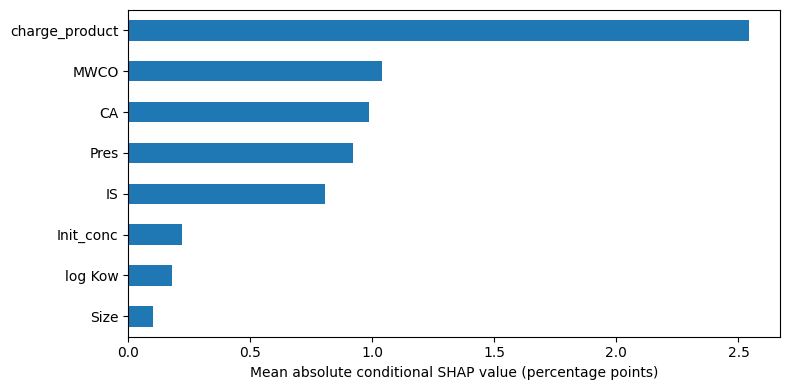

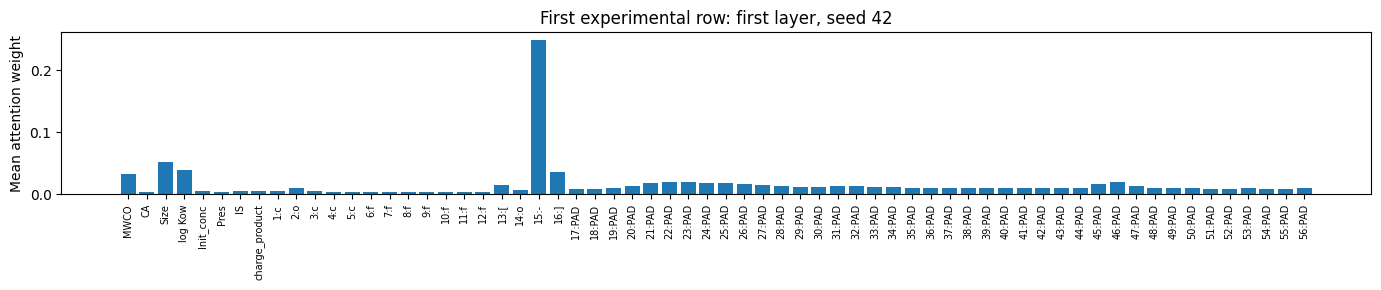

/tmp/ipykernel_2623/2433280343.py:36: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(np.array(shap_values),physical_test.iloc[explain_rows].to_numpy(),feature_names=feature_labels,show=False)


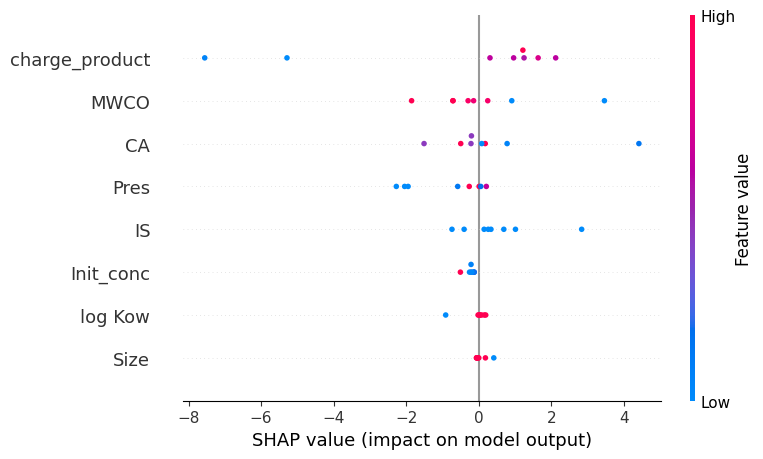

In [9]:
cfg=experiments[best_mode];FF_LAYERS=cfg['ff']
frame=prepare(train,best_mode);other=prepare(test,best_mode)
_,(X_test,),scaler,tokenizer=inputs(frame,[other])
mean=float(y_train.mean()) if cfg['scaled'] else 0.
std=float(y_train.std()) if cfg['scaled'] else 1.
ensemble=[]
for seed in seeds:
 model=Transformer(**params);model(tf.zeros((1,64)));model.load_weights(cache/f'{best_mode}_{seed}.weights.h5');ensemble.append(model)
def predict_encoded(values):
 values=np.asarray(values,dtype=np.float32)
 return np.mean([np.concatenate([model(values[a:a+64],training=False).numpy().ravel() for a in range(0,len(values),64)]) for model in ensemble],axis=0)*std+mean
assert np.allclose(predict_encoded(X_test),test_prediction,atol=2e-4)
physical_train=frame[input_vars].copy();physical_test=other[input_vars].copy()
background=physical_train.iloc[np.random.default_rng(42).choice(len(train),min(SHAP_BACKGROUND,len(train)),replace=False)].to_numpy()
explain_rows=np.linspace(0,len(test)-1,min(SHAP_ROWS,len(test)),dtype=int);shap_values=[]
for row in explain_rows:
 def predict_physics(values):
  physical=scaler.transform(pd.DataFrame(values,columns=input_vars))
  tokens=np.repeat(X_test[row:row+1,8:],len(values),axis=0)
  return predict_encoded(np.concatenate([physical,tokens],axis=1))
 explainer=shap.Explainer(predict_physics,shap.maskers.Independent(background),algorithm='permutation',feature_names=input_vars,seed=42)
 explanation=explainer(physical_test.iloc[row:row+1].to_numpy(),max_evals=SHAP_CYCLES*(2*len(input_vars)+1))
 assert np.allclose(explanation.base_values+explanation.values.sum(1),test_prediction[row],atol=.001)
 shap_values.append(explanation.values[0])
labels=[('log10 concentration (nmol/L)' if cfg['log'] and name=='Init_conc' else name) for name in input_vars]
importance=pd.Series(np.mean(np.abs(shap_values),axis=0),index=labels).sort_values()
fig,ax=plt.subplots(figsize=(8,4));importance.plot.barh(ax=ax);ax.set_xlabel('Mean absolute conditional SHAP value (percentage points)');save_plot(fig,'conditional_shap')
pd.DataFrame(shap_values,columns=labels,index=explain_rows).to_csv(out/'conditional_shap.csv')
model=ensemble[0];encoded=model.encoder.pos_embedding(tf.constant(X_test[:1]));encoded=model.encoder.dropout(encoded,training=False)
layer=model.encoder.enc_layers[0].self_attention
_,attention=layer.mha(query=encoded,value=encoded,key=encoded,return_attention_scores=True,training=False)
a=attention.numpy()[0].mean(axis=(0,1));labels=input_vars+[f'{i+1}:{tokenizer.index_word.get(int(t),"PAD")}' for i,t in enumerate(X_test[0,8:])]
fig,ax=plt.subplots(figsize=(14,3));ax.bar(np.arange(64),a);ax.set_xticks(np.arange(64));ax.set_xticklabels(labels,rotation=90,fontsize=7);ax.set_ylabel('Mean attention weight');ax.set_title('First experimental row: first layer, seed 42');save_plot(fig,'attention')

feature_labels=[('log10 concentration (nmol/L)' if cfg['log'] and name=='Init_conc' else name) for name in input_vars]
shap.summary_plot(np.array(shap_values),physical_test.iloc[explain_rows].to_numpy(),feature_names=feature_labels,show=False)
save_plot(plt.gcf(),'shap_summary')


## 9. Predictions and exports

In [10]:
predictions=test[['ref_ID','PFAS','Membrane','SMILES']].copy()
predictions['Measured (%)']=y_test
for mode,p in final.items():predictions[experiments[mode]['name']]=p['test']
for name,table in [('experimental_predictions',predictions),('paper_comparison',comparison),
 ('all_models',results),('cv_scores',scores),('fold_scores',fold_scores),
 ('seed_scores',seed_scores),('subgroup_errors',subgroups),('bootstrap_intervals',intervals)]:
 table.to_csv(out/f'{name}.csv',index=False)
oof_table=train[['ref_ID','PFAS','Membrane','group']].copy();oof_table['Measured (%)']=y_train
for mode in experiments:oof_table[mode]=oof[(mode,locked['epochs'][mode])]
oof_table.to_csv(out/'oof_predictions.csv',index=False)
fold_ids=np.zeros(len(train),dtype=int)
for i,(_,b) in enumerate(folds):fold_ids[b]=i+1
oof_table.assign(Fold=fold_ids).to_csv(out/'fold_assignments.csv',index=False)
settings['selection']=locked
(out/'settings.json').write_text(json.dumps(settings,indent=2))
summary=(f"Selected by grouped validation: {experiments[best_mode]['name']} at {locked['epochs'][best_mode]} epochs. "
 f"CV RMSE: {chosen.loc[best_mode,'CV RMSE']:.4f} pp. Experimental RMSE: {metrics(y_test,test_prediction)['RMSE (pp)']:.4f} pp; "
 f"MAE: {metrics(y_test,test_prediction)['MAE (pp)']:.4f} pp. Published Transformer: 5.90 / 4.50 pp. "
 "All variants and unsuccessful outcomes are in all_models.csv. This exploratory comparison does not establish superiority over the published model. "
 "CV selection is not nested; the experimental set was previously inspected. Bootstrap intervals cover PFAS resampling within one study only. "
 "Full training weights, preprocessing and configuration are in the run subfolder. Numeric SHAP and attention have the limits stated in section 8.")
(out/'research_notes.txt').write_text(summary)
archive=shutil.make_archive(str(out.resolve()),'zip',root_dir=out)
print(summary);print('Results archive:',archive)
display(predictions.head())


Selected by grouped validation: Transformer + target scaling at 400 epochs. CV RMSE: 8.2269 pp. Experimental RMSE: 9.2284 pp; MAE: 6.8781 pp. Published Transformer: 5.90 / 4.50 pp. All variants and unsuccessful outcomes are in all_models.csv. This exploratory comparison does not establish superiority over the published model. CV selection is not nested; the experimental set was previously inspected. Bootstrap intervals cover PFAS resampling within one study only. Full training weights, preprocessing and configuration are in the run subfolder. Numeric SHAP and attention have the limits stated in section 8.
Results archive: /content/transformer_comparison_results.zip


,ref_ID,PFAS,Membrane,SMILES,Measured (%),Transformer baseline,Transformer + target scaling,Transformer + log concentration,Transformer + feed-forward correction
0,1,PFBA,NF90,COCCCFFFFFFF[O-],81.961093,89.585548,94.615471,91.043602,92.580299
1,1,PFPeA,NF90,COCCCCFFFFFFFFF[O-],89.863274,93.877235,93.089638,93.894142,95.265923
2,1,PFBS,NF90,CCCFFSOO[O-]FFCFFFFF,98.819583,96.140648,95.308899,96.975975,96.850380
3,1,PFHxA,NF90,COCCCCCFFFFFFFFFFF[O-],98.270808,98.809204,96.973816,97.806366,100.239479
4,1,PFPeS,NF90,CCCFFFFFCCFFSOO[O-]FFFF,98.560089,95.970032,96.512489,96.769249,96.760460


## 10. Molecular–membrane reliability analysis



,Model,PFAS,Membrane,n,RMSE (pp),MAE (pp),Bias (pp),Small group
0,Transformer baseline,FOSA,NF,1,11.612,11.612,11.612,True
1,Transformer baseline,FOSA,NF270,3,4.932,3.899,3.668,False
2,Transformer baseline,FOSA,NF270-PAA,1,12.187,12.187,12.187,True
3,Transformer baseline,FOSA,NF270-PEI,1,3.097,3.097,3.097,True
4,Transformer baseline,FOSA,NF90,1,5.014,5.014,5.014,True
...,...,...,...,...,...,...,...,...
215,Transformer + feed-forward correction,PFPeS,NF,1,4.496,4.496,4.496,True
216,Transformer + feed-forward correction,PFPeS,NF270,3,12.302,10.189,10.189,False
217,Transformer + feed-forward correction,PFPeS,NF270-PAA,1,1.673,1.673,1.673,True
218,Transformer + feed-forward correction,PFPeS,NF270-PEI,1,0.821,0.821,-0.821,True


,Model,n,RMSE (pp),MAE (pp),Bias (pp),Equal-pair RMSE (pp),Equal-pair MAE (pp),Observed pairs
0,Transformer baseline,77,7.316,5.510,3.140,6.312,4.737,55
1,Transformer + target scaling,77,9.228,6.878,5.510,7.892,5.661,55
2,Transformer + log concentration,77,7.097,5.128,3.447,6.136,4.395,55
3,Transformer + feed-forward correction,77,7.446,5.538,4.565,6.568,4.829,55


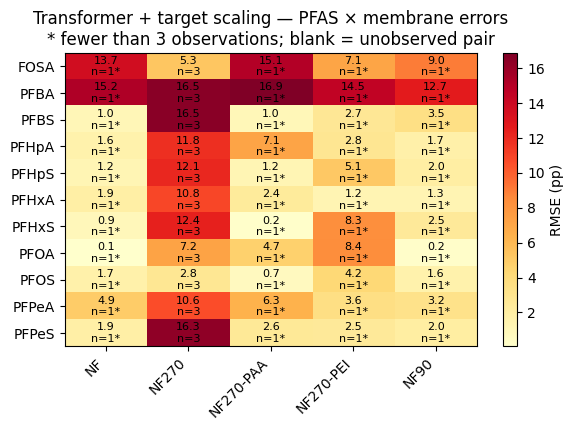

In [11]:
from pathlib import Path
import json as nv_json
import hashlib as nv_hashlib
import shutil as nv_shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler as NVScaler
from sklearn.neighbors import NearestNeighbors as NVNeighbors

nv_train=train.copy().reset_index(drop=True)
nv_test=test.copy().reset_index(drop=True)
nv_y=nv_test['Removal_rate'].to_numpy(dtype=float)
nv_primary=experiments[best_mode]['name']
nv_predictions={experiments[key]['name']:np.asarray(value['test'],dtype=float).ravel().copy() for key,value in final.items()}
nv_dir=Path('transformer_novelty_results');nv_dir.mkdir(exist_ok=True)
nv_min_n=3
for nv_name,nv_pred in nv_predictions.items():
 assert len(nv_pred)==len(nv_test) and np.isfinite(nv_pred).all(),nv_name
assert np.allclose(nv_y,np.asarray(y_test).ravel())

def nv_plot(fig,name):
 fig.tight_layout()
 for ext in ['png','pdf']:fig.savefig(nv_dir/f'{name}.{ext}',dpi=250,bbox_inches='tight')
 plt.show();plt.close(fig)

def nv_errors(y,p):
 return {'n':len(y),'RMSE (pp)':float(np.sqrt(np.mean((p-y)**2))),
         'MAE (pp)':float(np.mean(np.abs(p-y))), 'Bias (pp)':float(np.mean(p-y))}

nv_rows=[]
for nv_name,nv_pred in nv_predictions.items():
 for (nv_pfas,nv_mem),nv_idx in nv_test.groupby(['PFAS','Membrane']).groups.items():
  nv_idx=np.array(list(nv_idx))
  nv_rows.append({'Model':nv_name,'PFAS':nv_pfas,'Membrane':nv_mem,
   **nv_errors(nv_y[nv_idx],nv_pred[nv_idx])})
nv_pairs=pd.DataFrame(nv_rows)
nv_pairs['Small group']=nv_pairs['n']<nv_min_n
nv_pairs.to_csv(nv_dir/'molecule_membrane_errors.csv',index=False)
display(nv_pairs.round(3))
# Equal pair weighting prevents frequently measured pairs dominating every metric.
nv_balance=[]
for nv_name,nv_pred in nv_predictions.items():
 nv_g=nv_pairs[nv_pairs.Model==nv_name]
 nv_balance.append({'Model':nv_name,**nv_errors(nv_y,nv_pred),
  'Equal-pair RMSE (pp)':np.sqrt(np.mean(nv_g['RMSE (pp)']**2)),
  'Equal-pair MAE (pp)':nv_g['MAE (pp)'].mean(),'Observed pairs':len(nv_g)})
nv_balance=pd.DataFrame(nv_balance)
nv_balance.to_csv(nv_dir/'sample_vs_pair_weighting.csv',index=False);display(nv_balance.round(3))

nv_map=nv_pairs[nv_pairs.Model==nv_primary]
nv_grid=nv_map.pivot(index='PFAS',columns='Membrane',values='RMSE (pp)')
nv_counts=nv_map.pivot(index='PFAS',columns='Membrane',values='n').reindex_like(nv_grid)
nv_fig,nv_ax=plt.subplots(figsize=(max(6,.9*len(nv_grid.columns)),max(4,.4*len(nv_grid))))
nv_im=nv_ax.imshow(np.ma.masked_invalid(nv_grid.to_numpy()),aspect='auto',cmap='YlOrRd')
nv_ax.set_xticks(range(len(nv_grid.columns)),nv_grid.columns,rotation=45,ha='right')
nv_ax.set_yticks(range(len(nv_grid.index)),nv_grid.index)
for nv_i in range(len(nv_grid)):
 for nv_j in range(len(nv_grid.columns)):
  if np.isfinite(nv_grid.iloc[nv_i,nv_j]):
   nv_n=int(nv_counts.iloc[nv_i,nv_j]);nv_mark='*' if nv_n<nv_min_n else ''
   nv_ax.text(nv_j,nv_i,f'{nv_grid.iloc[nv_i,nv_j]:.1f}\nn={nv_n}{nv_mark}',ha='center',va='center',fontsize=8)
nv_fig.colorbar(nv_im,ax=nv_ax,label='RMSE (pp)')
nv_ax.set_title(nv_primary+' — PFAS × membrane errors\n* fewer than 3 observations; blank = unobserved pair')
nv_plot(nv_fig,'molecule_membrane_error_map')


## 11. Physical regimes and distance from training conditions




,Stratification,Regime,Model,n,RMSE (pp),MAE (pp),Bias (pp),Small group
0,Size regime × Charge magnitude,"('Above training median', 'Above training medi...",Transformer baseline,15,5.417,4.065,0.734,False
1,Size regime × Charge magnitude,"('Above training median', 'Above training medi...",Transformer + target scaling,15,6.442,4.202,1.772,False
2,Size regime × Charge magnitude,"('Above training median', 'Above training medi...",Transformer + log concentration,15,5.721,3.717,1.920,False
3,Size regime × Charge magnitude,"('Above training median', 'Above training medi...",Transformer + feed-forward correction,15,6.663,4.143,3.404,False
4,Size regime × Charge magnitude,"('Above training median', 'At/below training m...",Transformer baseline,3,6.455,5.871,-0.463,False
5,Size regime × Charge magnitude,"('Above training median', 'At/below training m...",Transformer + target scaling,3,7.052,6.769,3.964,False
6,Size regime × Charge magnitude,"('Above training median', 'At/below training m...",Transformer + log concentration,3,6.039,5.950,2.100,False
7,Size regime × Charge magnitude,"('Above training median', 'At/below training m...",Transformer + feed-forward correction,3,6.654,6.445,1.642,False
8,Size regime × Charge magnitude,"('At/below training median', 'Above training m...",Transformer baseline,39,4.724,3.912,3.655,False
9,Size regime × Charge magnitude,"('At/below training median', 'Above training m...",Transformer + target scaling,39,7.364,5.820,5.680,False


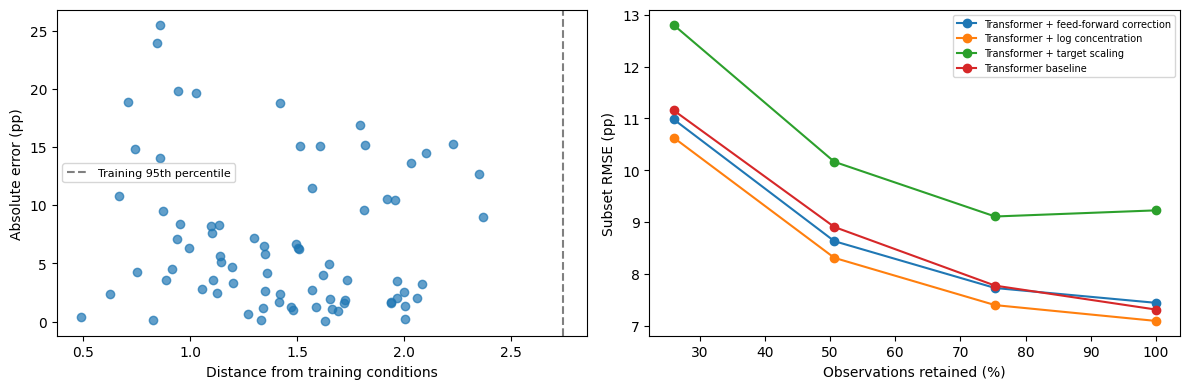

In [12]:
def nv_physical(frame):
 z=frame[['MWCO','CA','Size','log Kow','Init_conc','Pres','IS','charge_product']].astype(float).copy()
 z['Init_conc']=np.log10(z.Init_conc.clip(lower=1e-8))
 return z
nv_sc=NVScaler().fit(nv_physical(nv_train))
nv_z=nv_sc.transform(nv_physical(nv_train));nv_t=nv_sc.transform(nv_physical(nv_test))
nv_group=nv_train.ref_ID.astype(str)+'|'+nv_train.PFAS.astype(str)
nv_refdist=np.empty(len(nv_train))
for nv_g in nv_group.unique():
 nv_hold=(nv_group==nv_g).to_numpy();nv_k=min(5,int((~nv_hold).sum()))
 if nv_k<1:raise ValueError('Need at least two training reference–PFAS groups.')
 nv_nn=NVNeighbors(n_neighbors=nv_k).fit(nv_z[~nv_hold])
 nv_refdist[nv_hold]=nv_nn.kneighbors(nv_z[nv_hold])[0].mean(axis=1)
nv_nn=NVNeighbors(n_neighbors=min(5,len(nv_train))).fit(nv_z)
nv_distance=nv_nn.kneighbors(nv_t)[0].mean(axis=1)
nv_threshold=float(np.quantile(nv_refdist,.95))
nv_ratio_cut=float(np.median(nv_train.Mw/nv_train.MWCO))
nv_charge_cut=float(np.median(np.abs(nv_train.charge_product)))
nv_audit=nv_test[['ref_ID','PFAS','Membrane']].copy()
nv_audit['MW/MWCO']=nv_test.Mw/nv_test.MWCO
nv_audit['Size regime']=np.where(nv_audit['MW/MWCO']>nv_ratio_cut,'Above training median','At/below training median')
nv_audit['Charge magnitude']=np.where(np.abs(nv_test.charge_product)>nv_charge_cut,'Above training median','At/below training median')
nv_audit['Charge sign']=np.where(nv_test.charge_product>0,'Positive',np.where(nv_test.charge_product<0,'Negative','Zero'))
nv_audit['Distance']=nv_distance
nv_audit['Support']=np.where(nv_distance<=nv_threshold,'Within distance threshold','Beyond distance threshold')
nv_audit['Unseen PFAS']=~nv_test.PFAS.isin(nv_train.PFAS)
nv_audit['Unseen membrane']=~nv_test.Membrane.isin(nv_train.Membrane)
nv_regime=[]
for nv_keys in [['Size regime','Charge magnitude'],['Charge sign'],['Support'],['Unseen PFAS'],['Unseen membrane']]:
 for nv_label,nv_ix in nv_audit.groupby(nv_keys,dropna=False).groups.items():
  nv_ix=np.array(list(nv_ix))
  for nv_name,nv_pred in nv_predictions.items():
   nv_regime.append({'Stratification':' × '.join(nv_keys),'Regime':str(nv_label),'Model':nv_name,
    **nv_errors(nv_y[nv_ix],nv_pred[nv_ix]),'Small group':len(nv_ix)<nv_min_n})
nv_regime=pd.DataFrame(nv_regime)
nv_audit.to_csv(nv_dir/'training_support_per_observation.csv',index=False)
nv_regime.to_csv(nv_dir/'physical_regime_errors.csv',index=False);display(nv_regime.round(3))
nv_retained=[];nv_order=np.argsort(nv_distance,kind='stable')
for nv_fraction in [.25,.5,.75,1.]:
 nv_ix=nv_order[:max(1,int(np.ceil(nv_fraction*len(nv_y))))]
 for nv_name,nv_pred in nv_predictions.items():
  nv_retained.append({'Model':nv_name,'Coverage (%)':100*len(nv_ix)/len(nv_y),
   **nv_errors(nv_y[nv_ix],nv_pred[nv_ix])})
nv_retained=pd.DataFrame(nv_retained)
nv_retained.to_csv(nv_dir/'distance_risk_coverage.csv',index=False)
nv_fig,nv_axes=plt.subplots(1,2,figsize=(12,4))
nv_axes[0].scatter(nv_distance,np.abs(nv_predictions[nv_primary]-nv_y),alpha=.7)
nv_axes[0].axvline(nv_threshold,color='gray',ls='--',label='Training 95th percentile')
nv_axes[0].set(xlabel='Distance from training conditions',ylabel='Absolute error (pp)');nv_axes[0].legend(fontsize=8)
for nv_name,nv_g in nv_retained.groupby('Model'):
 nv_axes[1].plot(nv_g['Coverage (%)'],nv_g['RMSE (pp)'],'o-',label=nv_name)
nv_axes[1].set(xlabel='Observations retained (%)',ylabel='Subset RMSE (pp)');nv_axes[1].legend(fontsize=7)
nv_plot(nv_fig,'training_support_and_errors')


## 12. Does uncertainty identify unreliable predictions?



Uncertainty definition: Across-seed prediction SD (pp)
Spearman uncertainty–absolute-error association: 0.008


,Coverage (%),n,RMSE (pp),MAE (pp),Bias (pp)
0,25.974,20,8.199,6.339,4.240
1,50.649,39,7.499,5.960,3.813
2,75.325,58,8.232,6.324,4.702
3,100.000,77,9.228,6.878,5.510


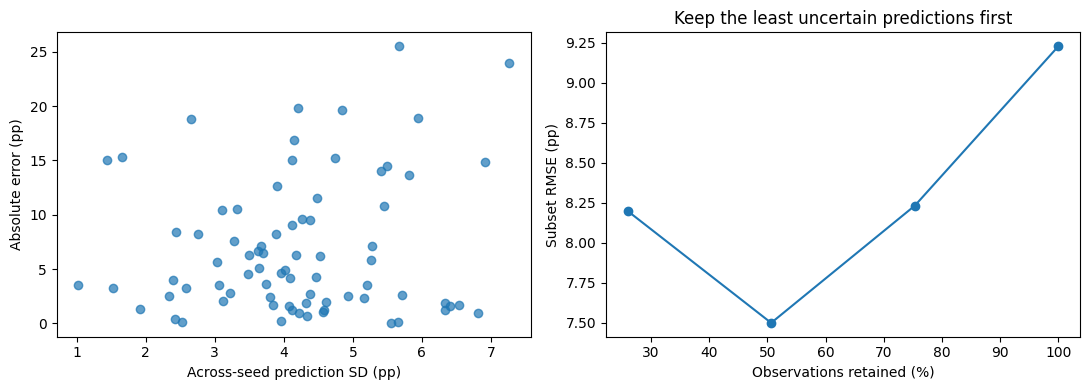

In [13]:
nv_u=np.std(np.asarray(final[best_mode]['seed_test']),axis=0,ddof=1)
nv_uncertainty_name='Across-seed prediction SD (pp)'
nv_u=np.asarray(nv_u,dtype=float).ravel()
assert nv_u.shape==nv_y.shape and np.isfinite(nv_u).all()
nv_abs=np.abs(nv_predictions[nv_primary]-nv_y)
nv_rho=pd.Series(nv_u).rank().corr(pd.Series(nv_abs).rank()) if np.ptp(nv_u)>0 and np.ptp(nv_abs)>0 else np.nan
nv_urows=[];nv_uorder=np.argsort(nv_u,kind='stable')
for nv_fraction in [.25,.5,.75,1.]:
 nv_ix=nv_uorder[:max(1,int(np.ceil(nv_fraction*len(nv_y))))]
 nv_urows.append({'Coverage (%)':100*len(nv_ix)/len(nv_y),**nv_errors(nv_y[nv_ix],nv_predictions[nv_primary][nv_ix])})
nv_utable=pd.DataFrame(nv_urows)
nv_utable.to_csv(nv_dir/'uncertainty_risk_coverage.csv',index=False)
pd.DataFrame({'Score':nv_u,'Absolute error (pp)':nv_abs}).to_csv(nv_dir/'uncertainty_per_observation.csv',index=False)
print('Uncertainty definition:',nv_uncertainty_name)
print('Spearman uncertainty–absolute-error association:',round(nv_rho,3))
display(nv_utable.round(3))
nv_fig,nv_axes=plt.subplots(1,2,figsize=(11,4))
nv_axes[0].scatter(nv_u,nv_abs,alpha=.7);nv_axes[0].set(xlabel=nv_uncertainty_name,ylabel='Absolute error (pp)')
nv_axes[1].plot(nv_utable['Coverage (%)'],nv_utable['RMSE (pp)'],'o-')
nv_axes[1].set(xlabel='Observations retained (%)',ylabel='Subset RMSE (pp)',title='Keep the least uncertain predictions first')
nv_plot(nv_fig,'uncertainty_error_association')


## 13. Where do Transformer modifications help or hurt?



,Model,PFAS,Membrane,n,RMSE (pp),MAE (pp),Bias (pp),Small group,Baseline RMSE (pp),RMSE difference (pp)
55,Transformer + target scaling,FOSA,NF,1,13.661,13.661,13.661,True,11.612,2.050
56,Transformer + target scaling,FOSA,NF270,3,5.284,4.213,3.935,False,4.932,0.352
57,Transformer + target scaling,FOSA,NF270-PAA,1,15.056,15.056,15.056,True,12.187,2.868
58,Transformer + target scaling,FOSA,NF270-PEI,1,7.079,7.079,7.079,True,3.097,3.982
59,Transformer + target scaling,FOSA,NF90,1,9.021,9.021,9.021,True,5.014,4.007
...,...,...,...,...,...,...,...,...,...,...
215,Transformer + feed-forward correction,PFPeS,NF,1,4.496,4.496,4.496,True,1.081,3.415
216,Transformer + feed-forward correction,PFPeS,NF270,3,12.302,10.189,10.189,False,12.456,-0.154
217,Transformer + feed-forward correction,PFPeS,NF270-PAA,1,1.673,1.673,1.673,True,0.576,1.097
218,Transformer + feed-forward correction,PFPeS,NF270-PEI,1,0.821,0.821,-0.821,True,3.385,-2.564


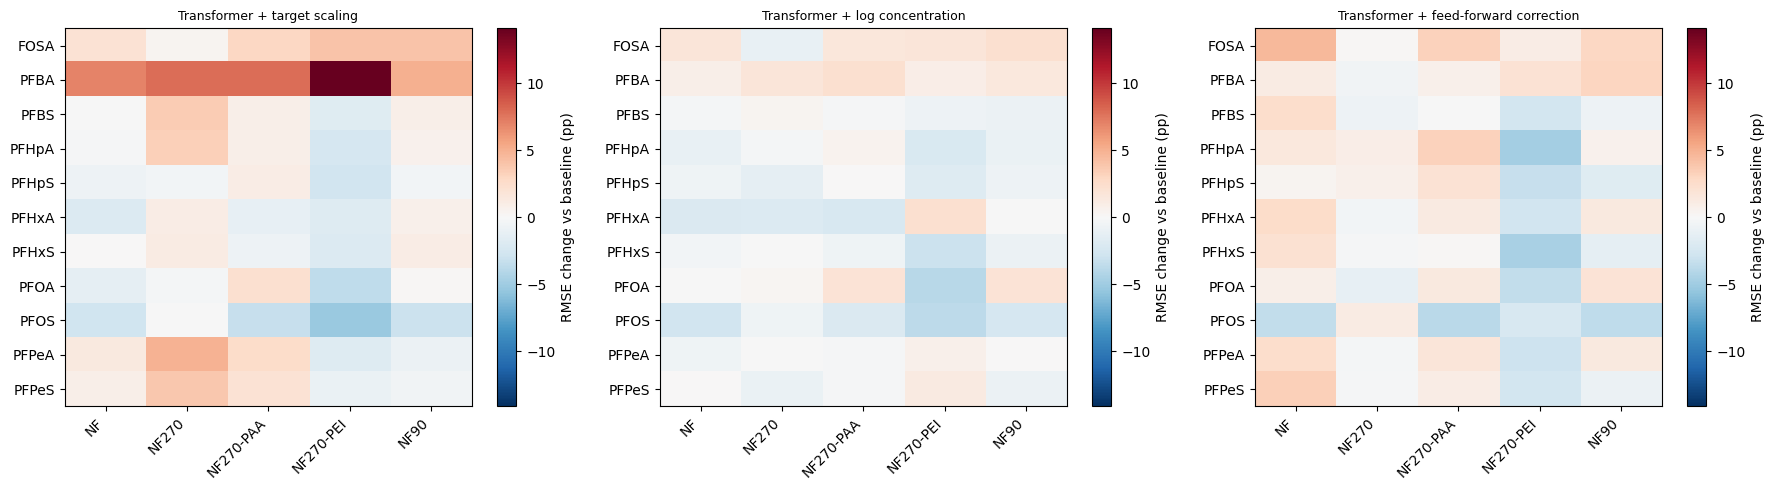

,Model,Difference vs baseline (pp),95% lower,95% upper,PFAS clusters
0,Transformer + target scaling,1.912,0.371,3.650,11
1,Transformer + log concentration,-0.219,-0.741,0.334,11
2,Transformer + feed-forward correction,0.129,-0.393,0.740,11


In [14]:
nv_base_name=experiments['baseline']['name']
nv_base=nv_pairs[nv_pairs.Model==nv_base_name][['PFAS','Membrane','RMSE (pp)']].rename(columns={'RMSE (pp)':'Baseline RMSE (pp)'})
nv_delta=nv_pairs.merge(nv_base,on=['PFAS','Membrane'],validate='many_to_one')
nv_delta['RMSE difference (pp)']=nv_delta['RMSE (pp)']-nv_delta['Baseline RMSE (pp)']
nv_delta.to_csv(nv_dir/'paired_molecule_membrane_differences.csv',index=False)
display(nv_delta[nv_delta.Model!=nv_base_name].round(3))
nv_maps=[nv_name for nv_name in nv_predictions if nv_name!=nv_base_name]
nv_fig,nv_axes=plt.subplots(1,len(nv_maps),figsize=(6*len(nv_maps),max(5,.4*nv_test.PFAS.nunique())),squeeze=False)
nv_limit=max(.01,float(np.max(np.abs(nv_delta['RMSE difference (pp)']))))
for nv_ax,nv_name in zip(nv_axes.ravel(),nv_maps):
 nv_g=nv_delta[nv_delta.Model==nv_name]
 nv_grid=nv_g.pivot(index='PFAS',columns='Membrane',values='RMSE difference (pp)')
 nv_im=nv_ax.imshow(np.ma.masked_invalid(nv_grid.to_numpy()),aspect='auto',cmap='RdBu_r',vmin=-nv_limit,vmax=nv_limit)
 nv_ax.set_xticks(range(len(nv_grid.columns)),nv_grid.columns,rotation=45,ha='right')
 nv_ax.set_yticks(range(len(nv_grid.index)),nv_grid.index);nv_ax.set_title(nv_name,fontsize=9)
 nv_fig.colorbar(nv_im,ax=nv_ax,label='RMSE change vs baseline (pp)')
nv_plot(nv_fig,'modification_benefit_by_molecule_membrane')
nv_clusters=[np.array(list(ix)) for ix in nv_test.groupby('PFAS').groups.values()]
nv_rng=np.random.default_rng(42)
nv_resamples=[np.concatenate([nv_clusters[j] for j in nv_rng.integers(0,len(nv_clusters),len(nv_clusters))]) for _ in range(2000)]
nv_intervals=[]
for nv_name,nv_pred in nv_predictions.items():
 if nv_name==nv_base_name:continue
 nv_bs=[]
 for nv_ix in nv_resamples:
  nv_bs.append(nv_errors(nv_y[nv_ix],nv_pred[nv_ix])['RMSE (pp)']-nv_errors(nv_y[nv_ix],nv_predictions[nv_base_name][nv_ix])['RMSE (pp)'])
 nv_lo,nv_hi=np.percentile(nv_bs,[2.5,97.5])
 nv_intervals.append({'Model':nv_name,'Difference vs baseline (pp)':nv_errors(nv_y,nv_pred)['RMSE (pp)']-nv_errors(nv_y,nv_predictions[nv_base_name])['RMSE (pp)'],
 '95% lower':nv_lo,'95% upper':nv_hi,'PFAS clusters':len(nv_clusters)})
nv_intervals=pd.DataFrame(nv_intervals);nv_intervals.to_csv(nv_dir/'paired_pfas_bootstrap.csv',index=False)
display(nv_intervals.round(3))


## 14. Exports and research contribution



In [15]:
nv_key_cols=['ref_ID','PFAS','Membrane','MWCO','CA','Size','log Kow','Init_conc','Pres','IS','charge_product','Mw','pH','pKa','IEP']
def nv_row_key(row):
 vals=[]
 for key in nv_key_cols:
  value=row[key]
  vals.append(str(value) if key in ['PFAS','Membrane'] else format(float(value),'.10g'))
 return nv_hashlib.sha256(nv_json.dumps(vals,separators=(',',':')).encode()).hexdigest()
nv_export=nv_audit.copy();nv_export['Fingerprint']=nv_test.apply(nv_row_key,axis=1)
nv_export['Duplicate']=nv_export.groupby('Fingerprint').cumcount()
nv_export['Row key']=nv_export.Fingerprint+'-'+nv_export.Duplicate.astype(str)
nv_export['Measured (%)']=nv_y
for nv_name,nv_pred in nv_predictions.items():nv_export[nv_name]=nv_pred
nv_export.to_csv(nv_dir/'predictions_for_cross_notebook_comparison.csv',index=False)
nv_settings={'primary_model':nv_primary,'distance_features':list(nv_physical(nv_train).columns),
 'training_distance_95th_percentile':nv_threshold,'size_training_median':nv_ratio_cut,
 'absolute_charge_training_median':nv_charge_cut,'distance_neighbours':5,
 'uncertainty_definition':nv_uncertainty_name,'uncertainty_error_spearman':None if pd.isna(nv_rho) else float(nv_rho),
 'minimum_group_count_flag':nv_min_n,'external_test_previously_inspected':True,
 'training_rows':len(nv_train),'test_rows':len(nv_test),
 'unchanged_original_sections':list(range(1,10)),'new_sections':list(range(10,15))}
(nv_dir/'analysis_settings.json').write_text(nv_json.dumps(nv_settings,indent=2))
nv_archive=nv_shutil.make_archive(str(nv_dir.resolve()),'zip',root_dir=nv_dir)
print('Additional figures, tables, row-aligned predictions and settings:',nv_archive)


Additional figures, tables, row-aligned predictions and settings: /content/transformer_novelty_results.zip
